Libraries imported successfully!

First five rows:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),Species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa



Dataset Information:
Total Records: 150
Total Features: 4
Target Classes: ['setosa' 'versicolor' 'virginica']

Statistical Summary:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


Training Data: (120, 4)
Testing Data: (30, 4)

SVM Pipeline created successfully!

Cross Validation Scores:
[0.91666667 1.         0.95833333 0.95833333 1.        ]

Mean Cross Validation Accuracy: 0.9667
Standard Deviation: 0.0312


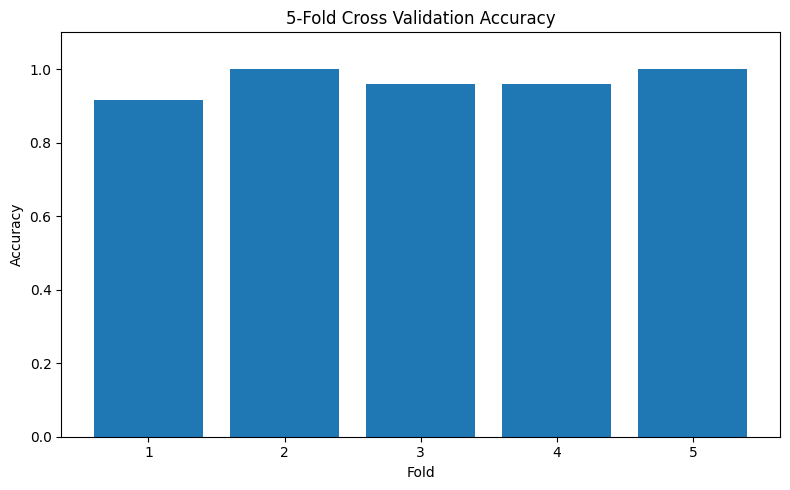

Fitting 5 folds for each of 24 candidates, totalling 120 fits

Best Parameters:
{'svm__C': 0.1, 'svm__gamma': 'scale', 'svm__kernel': 'linear'}

Best Cross Validation Accuracy:
0.975

Test Accuracy: 0.9333

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



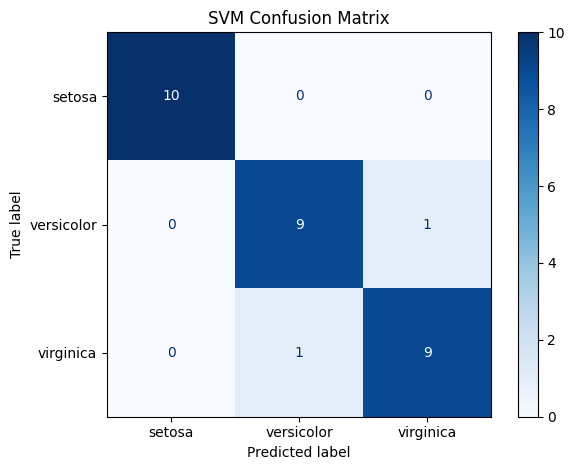


Top GridSearchCV Results:


,param_svm__C,param_svm__kernel,param_svm__gamma,mean_test_score,std_test_score
0,0.1,linear,scale,0.975000,0.033333
3,0.1,linear,auto,0.975000,0.033333
6,1.0,linear,scale,0.975000,0.020412
9,1.0,linear,auto,0.975000,0.020412
13,10.0,rbf,scale,0.966667,0.016667
14,10.0,poly,scale,0.966667,0.031180
10,1.0,rbf,auto,0.966667,0.031180
7,1.0,rbf,scale,0.966667,0.031180
21,100.0,linear,auto,0.966667,0.016667
18,100.0,linear,scale,0.966667,0.016667



Model saved successfully!
Saved Location: models/optimized_svm_model.pkl

Model loaded successfully!

New Data Prediction:
Predicted Species: setosa
Actual Species: setosa


,Predicted Species,Actual Species
0,setosa,setosa
1,virginica,virginica
2,versicolor,versicolor
3,versicolor,versicolor
4,setosa,setosa



Original Model Accuracy: 0.9333
Loaded Model Accuracy: 0.9333
Predictions Match: True


,Metric,Score
0,Mean Cross Validation Accuracy,0.966667
1,Best GridSearchCV Accuracy,0.975000
2,Test Accuracy,0.933333
3,Loaded Model Accuracy,0.933333



WEEK 4 ASSIGNMENT COMPLETED!

Generated Files:
outputs/cross_validation_accuracy.png
outputs/gridsearch_results.csv
outputs/model_evaluation_summary.csv
outputs/svm_confusion_matrix.png
models/optimized_svm_model.pkl


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [1]:

# ============================================================
# WEEK 4 - MODEL EVALUATION & OPTIMIZATION
# ============================================================

# 1. INSTALL AND IMPORT LIBRARIES

%pip install -q numpy pandas matplotlib seaborn scikit-learn joblib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import os

from sklearn.datasets import load_iris
from sklearn.model_selection import (
    train_test_split,
    cross_val_score,
    GridSearchCV
)
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

os.makedirs("outputs", exist_ok=True)
os.makedirs("models", exist_ok=True)

print("Libraries imported successfully!")


# ============================================================
# 2. LOAD IRIS DATASET
# ============================================================

iris = load_iris()

X = iris.data
y = iris.target

df = pd.DataFrame(X, columns=iris.feature_names)
df["Species"] = [
    iris.target_names[i] for i in y
]

print("\nFirst five rows:")
display(df.head())

print("\nDataset Information:")
print("Total Records:", X.shape[0])
print("Total Features:", X.shape[1])
print("Target Classes:", iris.target_names)

print("\nStatistical Summary:")
display(df.describe())


# ============================================================
# 3. SPLIT DATASET INTO TRAINING AND TESTING SETS
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)


# ============================================================
# 4. CREATE SVM PIPELINE
# ============================================================

svm_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC())
])

print("\nSVM Pipeline created successfully!")


# ============================================================
# 5. CROSS VALIDATION USING cross_val_score
# PRACTICE QUESTION 1
# ============================================================

cv_scores = cross_val_score(
    svm_pipeline,
    X_train,
    y_train,
    cv=5,
    scoring="accuracy"
)

print("\nCross Validation Scores:")
print(cv_scores)

print("\nMean Cross Validation Accuracy:",
      round(cv_scores.mean(), 4))

print("Standard Deviation:",
      round(cv_scores.std(), 4))


# Visualize Cross Validation Scores

plt.figure(figsize=(8, 5))

plt.bar(
    range(1, 6),
    cv_scores
)

plt.title("5-Fold Cross Validation Accuracy")
plt.xlabel("Fold")
plt.ylabel("Accuracy")
plt.ylim(0, 1.1)
plt.xticks(range(1, 6))
plt.tight_layout()

plt.savefig(
    "outputs/cross_validation_accuracy.png",
    dpi=150
)

plt.show()


# ============================================================
# 6. IMPLEMENT GRIDSEARCHCV FOR SVM
# PRACTICE QUESTION 2
# ============================================================

param_grid = {
    "svm__C": [0.1, 1, 10, 100],
    "svm__kernel": ["linear", "rbf", "poly"],
    "svm__gamma": ["scale", "auto"]
}

grid_search = GridSearchCV(
    estimator=svm_pipeline,
    param_grid=param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

print("\nBest Parameters:")
print(grid_search.best_params_)

print("\nBest Cross Validation Accuracy:")
print(round(grid_search.best_score_, 4))

best_model = grid_search.best_estimator_


# ============================================================
# 7. EVALUATE OPTIMIZED SVM MODEL
# ============================================================

y_pred = best_model.predict(X_test)

test_accuracy = accuracy_score(y_test, y_pred)

print("\nTest Accuracy:",
      round(test_accuracy, 4))

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=iris.target_names
    )
)


# Confusion Matrix

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=iris.target_names
)

disp.plot(cmap="Blues")

plt.title("SVM Confusion Matrix")
plt.tight_layout()

plt.savefig(
    "outputs/svm_confusion_matrix.png",
    dpi=150
)

plt.show()


# ============================================================
# 8. GRIDSEARCHCV RESULTS
# ============================================================

results = pd.DataFrame(grid_search.cv_results_)

results = results[
    [
        "param_svm__C",
        "param_svm__kernel",
        "param_svm__gamma",
        "mean_test_score",
        "std_test_score"
    ]
]

results = results.sort_values(
    by="mean_test_score",
    ascending=False
)

print("\nTop GridSearchCV Results:")
display(results.head(10))

results.to_csv(
    "outputs/gridsearch_results.csv",
    index=False
)


# ============================================================
# 9. SAVE TRAINED MODEL USING JOBLIB
# PRACTICE QUESTION 3
# ============================================================

model_path = "models/optimized_svm_model.pkl"

joblib.dump(
    best_model,
    model_path
)

print("\nModel saved successfully!")
print("Saved Location:", model_path)


# ============================================================
# 10. LOAD MODEL USING JOBLIB
# PRACTICE QUESTION 4
# ============================================================

loaded_model = joblib.load(model_path)

print("\nModel loaded successfully!")


# ============================================================
# 11. PREDICT ON NEW DATA
# ============================================================

# Take one unseen test sample

new_sample = X_test[0].reshape(1, -1)

prediction = loaded_model.predict(new_sample)

predicted_species = iris.target_names[prediction[0]]

actual_species = iris.target_names[y_test[0]]

print("\nNew Data Prediction:")
print("Predicted Species:", predicted_species)
print("Actual Species:", actual_species)


# Predict on multiple new samples

new_samples = X_test[:5]

predictions = loaded_model.predict(new_samples)

prediction_results = pd.DataFrame({
    "Predicted Species": [
        iris.target_names[i] for i in predictions
    ],
    "Actual Species": [
        iris.target_names[i] for i in y_test[:5]
    ]
})

display(prediction_results)


# ============================================================
# 12. VERIFY LOADED MODEL PERFORMANCE
# ============================================================

loaded_predictions = loaded_model.predict(X_test)

loaded_accuracy = accuracy_score(
    y_test,
    loaded_predictions
)

print("\nOriginal Model Accuracy:",
      round(test_accuracy, 4))

print("Loaded Model Accuracy:",
      round(loaded_accuracy, 4))

print(
    "Predictions Match:",
    np.array_equal(y_pred, loaded_predictions)
)


# ============================================================
# 13. SAVE FINAL RESULTS
# ============================================================

summary = pd.DataFrame({
    "Metric": [
        "Mean Cross Validation Accuracy",
        "Best GridSearchCV Accuracy",
        "Test Accuracy",
        "Loaded Model Accuracy"
    ],
    "Score": [
        cv_scores.mean(),
        grid_search.best_score_,
        test_accuracy,
        loaded_accuracy
    ]
})

display(summary)

summary.to_csv(
    "outputs/model_evaluation_summary.csv",
    index=False
)


# ============================================================
# 14. CREATE ZIP OF ALL OUTPUTS
# ============================================================

import zipfile

with zipfile.ZipFile(
    "Week4_Model_Evaluation_Results.zip",
    "w",
    zipfile.ZIP_DEFLATED
) as zip_file:

    for folder in ["outputs", "models"]:

        for root, dirs, files_list in os.walk(folder):

            for filename in files_list:

                file_path = os.path.join(
                    root,
                    filename
                )

                zip_file.write(file_path)


print("\n====================================")
print("WEEK 4 ASSIGNMENT COMPLETED!")
print("====================================")

print("\nGenerated Files:")

for folder in ["outputs", "models"]:

    for filename in sorted(os.listdir(folder)):

        print(os.path.join(folder, filename))


# Download results in Google Colab

from google.colab import files

files.download("Week4_Model_Evaluation_Results.zip")


Libraries imported successfully!
Upload Mall_Customers.csv


Saving Mall_Customers - Mall_Customers.csv to Mall_Customers - Mall_Customers.csv

Dataset loaded successfully!


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40



Dataset Shape: (200, 5)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB

Missing Values:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

Cleaned Dataset:


,Age,Annual Income (k$),Spending Score (1-100)
0,19,15,39
1,21,15,81
2,20,16,6
3,23,16,77
4,31,17,40



Statistical Summary:


,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000
mean,38.850000,60.560000,50.200000
std,13.969007,26.264721,25.823522
min,18.000000,15.000000,1.000000
25%,28.750000,41.500000,34.750000
50%,36.000000,61.500000,50.000000
75%,49.000000,78.000000,73.000000
max,70.000000,137.000000,99.000000


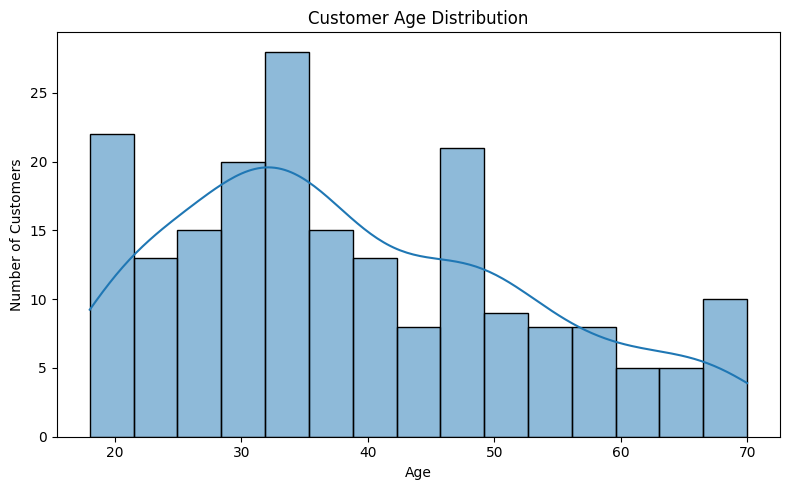

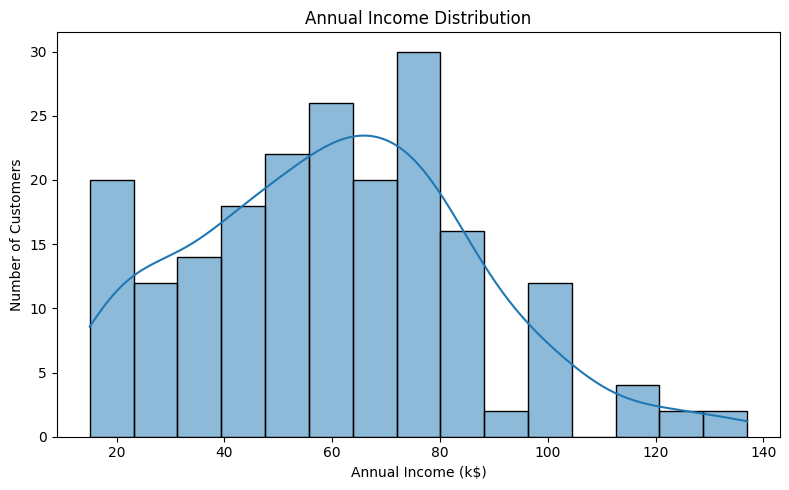

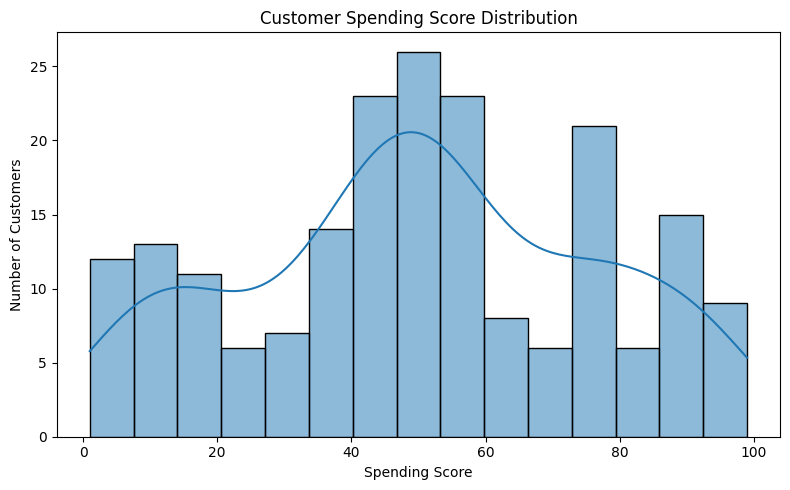


Feature Scaling Completed!


,Age,Annual Income (k$),Spending Score (1-100)
0,-1.424569,-1.738999,-0.434801
1,-1.281035,-1.738999,1.195704
2,-1.352802,-1.700830,-1.715913
3,-1.137502,-1.700830,1.040418
4,-0.563369,-1.662660,-0.395980


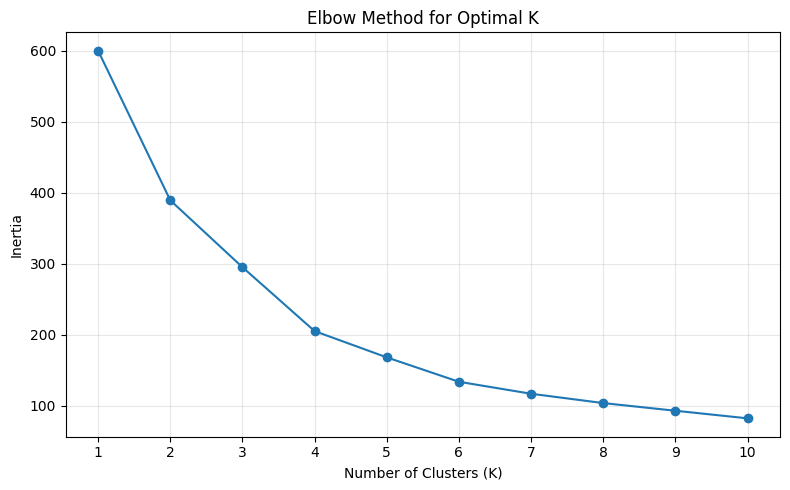


K-Means Clustering Completed!

Cluster Distribution:
Cluster
0    68
1    41
2    91
Name: count, dtype: int64

Silhouette Score: 0.3578

Customer Segmentation Results:


,Age,Annual Income (k$),Spending Score (1-100),Cluster,Customer Segment
0,19,15,39,0,Medium Spenders
1,21,15,81,0,Medium Spenders
2,20,16,6,0,Medium Spenders
3,23,16,77,0,Medium Spenders
4,31,17,40,0,Medium Spenders
5,22,17,76,0,Medium Spenders
6,35,18,6,0,Medium Spenders
7,23,18,94,0,Medium Spenders
8,64,19,3,2,Low Spenders
9,30,19,72,0,Medium Spenders


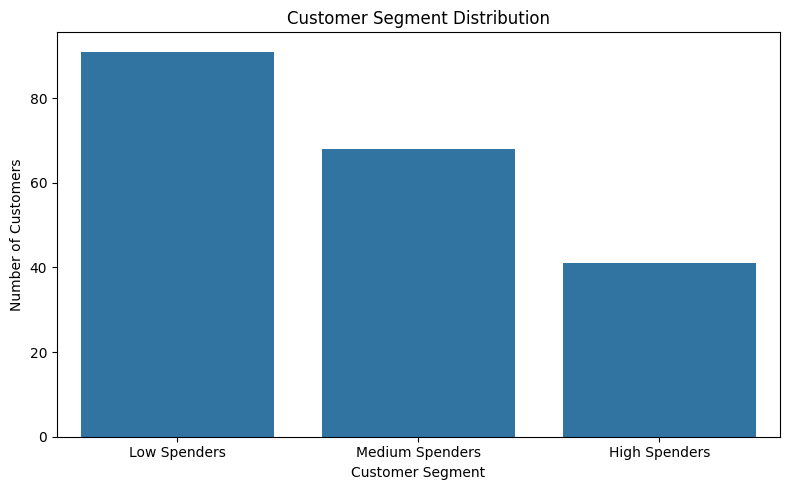

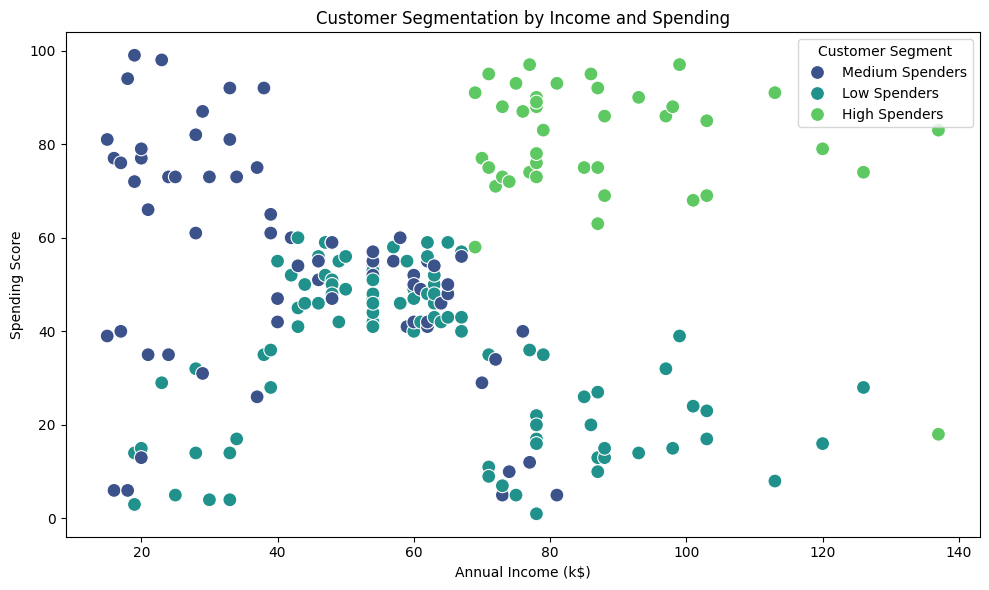

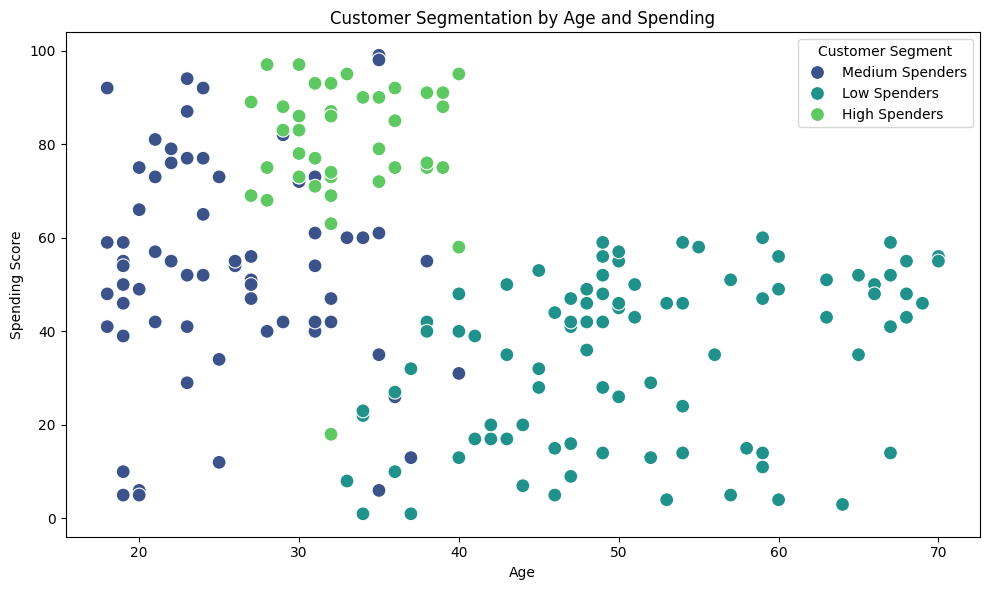

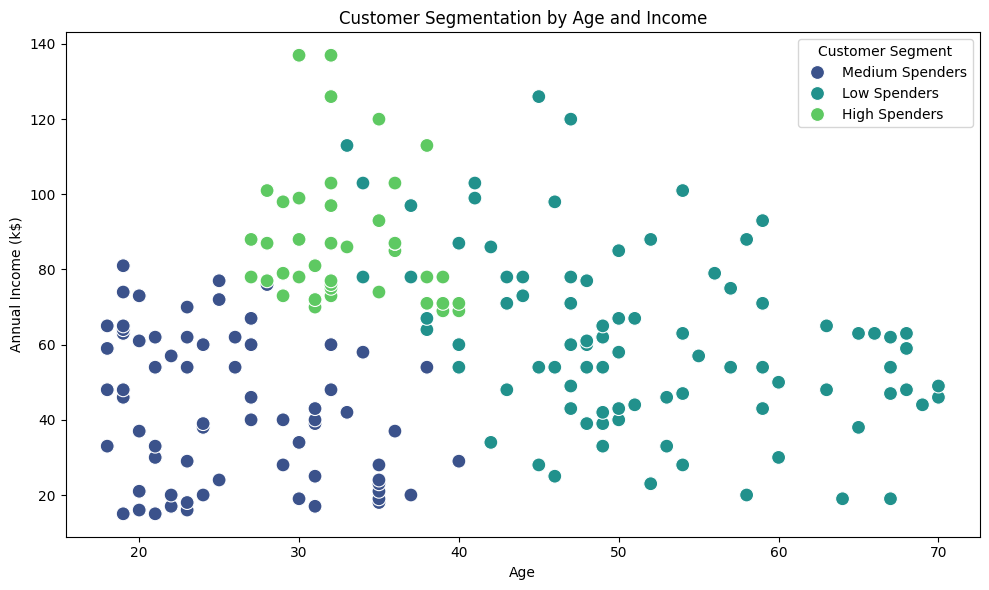


Customer Segment Analysis:


,Total_Customers,Average_Age,Average_Income,Average_Spending_Score
Customer Segment,,,,
High Spenders,41,32.85,87.34,79.98
Low Spenders,91,51.27,61.80,34.21
Medium Spenders,68,25.84,42.75,53.65



Model saved successfully using Joblib!

Model loaded successfully!

New Customer Predictions:


,Age,Annual Income (k$),Spending Score (1-100),Cluster,Customer Segment
0,25,25,80,0,Medium Spenders
1,40,70,50,2,Low Spenders
2,55,100,20,2,Low Spenders



All results saved successfully!

WEEK 4 MAJOR PROJECT COMPLETED!

Total Customers: 200

Customer Segment Counts:
Customer Segment
Low Spenders       91
Medium Spenders    68
High Spenders      41
Name: count, dtype: int64

Silhouette Score: 0.3578

Generated Files:
outputs/cross_validation_accuracy.png
outputs/customer_segment_analysis.csv
outputs/customer_segmentation_results.csv
outputs/gridsearch_results.csv
outputs/model_evaluation_summary.csv
outputs/new_customer_predictions.csv
outputs/svm_confusion_matrix.png
models/customer_segmentation_model.pkl
models/optimized_svm_model.pkl
visualizations/age_distribution.png
visualizations/age_vs_income.png
visualizations/age_vs_spending.png
visualizations/customer_segment_distribution.png
visualizations/elbow_method.png
visualizations/income_distribution.png
visualizations/income_vs_spending.png
visualizations/spending_distribution.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [2]:

# ============================================================
# WEEK 4 MAJOR PROJECT
# CUSTOMER SEGMENTATION USING K-MEANS CLUSTERING
# ============================================================

# 1. INSTALL AND IMPORT LIBRARIES

%pip install -q numpy pandas matplotlib seaborn scikit-learn joblib

import os
import zipfile
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.pipeline import Pipeline
from sklearn.metrics import silhouette_score

os.makedirs("outputs", exist_ok=True)
os.makedirs("models", exist_ok=True)
os.makedirs("visualizations", exist_ok=True)

print("Libraries imported successfully!")


# ============================================================
# 2. UPLOAD MALL CUSTOMERS DATASET
# ============================================================

print("Upload Mall_Customers.csv")

uploaded = files.upload()

filename = next(iter(uploaded))

df = pd.read_csv(filename)

df.columns = df.columns.str.strip()

print("\nDataset loaded successfully!")
display(df.head())

print("\nDataset Shape:", df.shape)
print("\nDataset Information:")
df.info()


# ============================================================
# 3. DATA CLEANING AND PREPROCESSING
# ============================================================

required_columns = [
    "Age",
    "Annual Income (k$)",
    "Spending Score (1-100)"
]

for column in required_columns:
    if column not in df.columns:
        raise ValueError(f"Missing required column: {column}")

# Check missing values

print("\nMissing Values:")
print(df.isnull().sum())

# Remove duplicate records

df = df.drop_duplicates()

# Handle missing numerical values

for column in required_columns:
    df[column] = pd.to_numeric(
        df[column], errors="coerce"
    )
    df[column] = df[column].fillna(
        df[column].median()
    )

# Select features for clustering

X = df[required_columns].copy()

print("\nCleaned Dataset:")
display(X.head())

print("\nStatistical Summary:")
display(X.describe())


# ============================================================
# 4. EXPLORATORY DATA ANALYSIS
# ============================================================

plt.figure(figsize=(8, 5))

sns.histplot(
    df["Age"],
    bins=15,
    kde=True
)

plt.title("Customer Age Distribution")
plt.xlabel("Age")
plt.ylabel("Number of Customers")
plt.tight_layout()

plt.savefig(
    "visualizations/age_distribution.png",
    dpi=150
)

plt.show()


plt.figure(figsize=(8, 5))

sns.histplot(
    df["Annual Income (k$)"],
    bins=15,
    kde=True
)

plt.title("Annual Income Distribution")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Number of Customers")
plt.tight_layout()

plt.savefig(
    "visualizations/income_distribution.png",
    dpi=150
)

plt.show()


plt.figure(figsize=(8, 5))

sns.histplot(
    df["Spending Score (1-100)"],
    bins=15,
    kde=True
)

plt.title("Customer Spending Score Distribution")
plt.xlabel("Spending Score")
plt.ylabel("Number of Customers")
plt.tight_layout()

plt.savefig(
    "visualizations/spending_distribution.png",
    dpi=150
)

plt.show()


# ============================================================
# 5. FEATURE SCALING
# ============================================================

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("\nFeature Scaling Completed!")

scaled_df = pd.DataFrame(
    X_scaled,
    columns=required_columns
)

display(scaled_df.head())


# ============================================================
# 6. ELBOW METHOD TO FIND OPTIMAL K
# ============================================================

inertia_values = []

for k in range(1, 11):

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    model.fit(X_scaled)

    inertia_values.append(model.inertia_)


plt.figure(figsize=(8, 5))

plt.plot(
    range(1, 11),
    inertia_values,
    marker="o"
)

plt.title("Elbow Method for Optimal K")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.xticks(range(1, 11))
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "visualizations/elbow_method.png",
    dpi=150
)

plt.show()


# ============================================================
# 7. APPLY K-MEANS CLUSTERING
# ============================================================

kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

cluster_labels = kmeans.fit_predict(X_scaled)

df["Cluster"] = cluster_labels

print("\nK-Means Clustering Completed!")

print("\nCluster Distribution:")
print(df["Cluster"].value_counts().sort_index())


# ============================================================
# 8. EVALUATE CLUSTERING MODEL
# ============================================================

silhouette = silhouette_score(
    X_scaled,
    cluster_labels
)

print("\nSilhouette Score:",
      round(silhouette, 4))


# ============================================================
# 9. LABEL CUSTOMER SEGMENTS
# LOW, MEDIUM AND HIGH SPENDERS
# ============================================================

cluster_spending = df.groupby(
    "Cluster"
)["Spending Score (1-100)"].mean()

sorted_clusters = cluster_spending.sort_values().index.tolist()

segment_mapping = {
    sorted_clusters[0]: "Low Spenders",
    sorted_clusters[1]: "Medium Spenders",
    sorted_clusters[2]: "High Spenders"
}

df["Customer Segment"] = df["Cluster"].map(
    segment_mapping
)

print("\nCustomer Segmentation Results:")

display(
    df[
        [
            "Age",
            "Annual Income (k$)",
            "Spending Score (1-100)",
            "Cluster",
            "Customer Segment"
        ]
    ].head(10)
)


# ============================================================
# 10. CUSTOMER SEGMENT DISTRIBUTION
# ============================================================

segment_counts = df["Customer Segment"].value_counts()

plt.figure(figsize=(8, 5))

sns.barplot(
    x=segment_counts.index,
    y=segment_counts.values
)

plt.title("Customer Segment Distribution")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")
plt.tight_layout()

plt.savefig(
    "visualizations/customer_segment_distribution.png",
    dpi=150
)

plt.show()


# ============================================================
# 11. VISUALIZE CUSTOMERS BY INCOME AND SPENDING SCORE
# ============================================================

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    hue="Customer Segment",
    palette="viridis",
    s=100
)

plt.title("Customer Segmentation by Income and Spending")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score")
plt.legend(title="Customer Segment")
plt.tight_layout()

plt.savefig(
    "visualizations/income_vs_spending.png",
    dpi=150
)

plt.show()


# ============================================================
# 12. VISUALIZE CUSTOMERS BY AGE AND SPENDING SCORE
# ============================================================

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="Age",
    y="Spending Score (1-100)",
    hue="Customer Segment",
    palette="viridis",
    s=100
)

plt.title("Customer Segmentation by Age and Spending")
plt.xlabel("Age")
plt.ylabel("Spending Score")
plt.tight_layout()

plt.savefig(
    "visualizations/age_vs_spending.png",
    dpi=150
)

plt.show()


# ============================================================
# 13. VISUALIZE CUSTOMERS BY AGE AND INCOME
# ============================================================

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="Age",
    y="Annual Income (k$)",
    hue="Customer Segment",
    palette="viridis",
    s=100
)

plt.title("Customer Segmentation by Age and Income")
plt.xlabel("Age")
plt.ylabel("Annual Income (k$)")
plt.tight_layout()

plt.savefig(
    "visualizations/age_vs_income.png",
    dpi=150
)

plt.show()


# ============================================================
# 14. CUSTOMER SEGMENT ANALYSIS
# ============================================================

segment_analysis = df.groupby(
    "Customer Segment"
).agg(
    Total_Customers=("Customer Segment", "count"),
    Average_Age=("Age", "mean"),
    Average_Income=("Annual Income (k$)", "mean"),
    Average_Spending_Score=("Spending Score (1-100)", "mean")
).round(2)

print("\nCustomer Segment Analysis:")
display(segment_analysis)


# ============================================================
# 15. SAVE THE TRAINED MODEL USING JOBLIB
# ============================================================

clustering_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("kmeans", KMeans(
        n_clusters=3,
        random_state=42,
        n_init=10
    ))
])

clustering_pipeline.fit(X)

joblib.dump(
    clustering_pipeline,
    "models/customer_segmentation_model.pkl"
)

print("\nModel saved successfully using Joblib!")


# ============================================================
# 16. LOAD MODEL AND PREDICT NEW CUSTOMERS
# ============================================================

loaded_model = joblib.load(
    "models/customer_segmentation_model.pkl"
)

print("\nModel loaded successfully!")

new_customers = pd.DataFrame({
    "Age": [25, 40, 55],
    "Annual Income (k$)": [25, 70, 100],
    "Spending Score (1-100)": [80, 50, 20]
})

new_predictions = loaded_model.predict(new_customers)

new_customers["Cluster"] = new_predictions

new_customers["Customer Segment"] = (
    new_customers["Cluster"].map(segment_mapping)
)

print("\nNew Customer Predictions:")

display(new_customers)


# ============================================================
# 17. SAVE FINAL RESULTS
# ============================================================

df.to_csv(
    "outputs/customer_segmentation_results.csv",
    index=False
)

segment_analysis.to_csv(
    "outputs/customer_segment_analysis.csv"
)

new_customers.to_csv(
    "outputs/new_customer_predictions.csv",
    index=False
)

print("\nAll results saved successfully!")


# ============================================================
# 18. CREATE ZIP FILE OF ALL PROJECT DELIVERABLES
# ============================================================

zip_filename = "Week4_Customer_Segmentation_Project.zip"

with zipfile.ZipFile(
    zip_filename,
    "w",
    zipfile.ZIP_DEFLATED
) as zip_file:

    for folder in ["outputs", "models", "visualizations"]:

        for root, dirs, filenames in os.walk(folder):

            for filename in filenames:

                file_path = os.path.join(
                    root,
                    filename
                )

                zip_file.write(file_path)


# ============================================================
# 19. PROJECT COMPLETION SUMMARY
# ============================================================

print("\n======================================")
print("WEEK 4 MAJOR PROJECT COMPLETED!")
print("======================================")

print("\nTotal Customers:", len(df))

print("\nCustomer Segment Counts:")
print(df["Customer Segment"].value_counts())

print("\nSilhouette Score:", round(silhouette, 4))

print("\nGenerated Files:")

for folder in ["outputs", "models", "visualizations"]:

    for filename in sorted(os.listdir(folder)):

        print(os.path.join(folder, filename))


# Download all project deliverables

files.download(zip_filename)
